# 07. Wildfire Specialist Layer: Hierarchical Regime-Switching & Extreme Calibration

> **Course:** DSR301m – Data Science Research & Applied Machine Learning  
> **Mục tiêu:** Xây dựng và đánh giá thực nghiệm tầng mô hình chuyên biệt cho điều kiện thảm họa cháy rừng (Wildfire Specialist Layer) dựa trên kiến trúc **2-Stage Gating Mixture of Experts**.

### 1. Đặt Vấn Đề Khoa Học (Scientific Motivation)
- Hơn **95%** thời gian trong năm, chất lượng không khí California ở mức Tốt/Trung bình ($AQI \le 100$).
- Do đó, các mô hình tối chuẩn (Voting Ensemble, GBDT, Deep Learning) tối ưu hàm mất mát đối xứng (MSE/MAE) luôn có xu hướng **hồi quy về trung bình (regression toward the mean)**, dẫn đến việc đánh giá thấp nghiêm trọng (*under-prediction*) các đỉnh khói độc hại ($AQI > 300$) trong các đợt cháy rừng.
- **Giải pháp:** Tách biệt 2 trạng thái khí quyển thông qua bộ nhận diện điều kiện cháy kết hợp vật lý (`WildfireDetector`) và hòa trộn mềm với mô hình chuyên gia phạt lỗi bất đối xứng (`WildfireSpecialist`).
- **Kiểm chuẩn không rò rỉ (Out-of-Sample Benchmark):** Đánh giá trực diện trên các thảm họa thực tế giai đoạn **2024–2025** nằm hoàn toàn ngoài tập huấn luyện.

In [1]:
import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import lightgbm as lgb

# Định vị thư mục tương đối chuẩn dự án
BASE_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")
MODELS_DIR = os.path.join(ARTIFACTS_DIR, "models")
METRICS_DIR = os.path.join(ARTIFACTS_DIR, "metrics")
FIG_DIR = os.path.join(ARTIFACTS_DIR, "figures")
PRED_DIR = os.path.join(ARTIFACTS_DIR, "predictions")

def calculate_metrics(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    
    act_150, pred_150 = (y_true > 150), (y_pred > 150)
    tp_150 = np.sum(act_150 & pred_150)
    recall_150 = tp_150 / (np.sum(act_150) + 1e-8)
    prec_150 = tp_150 / (np.sum(pred_150) + 1e-8)
    f1_150 = 2 * prec_150 * recall_150 / (prec_150 + recall_150 + 1e-8)
    return {
        "R2": float(r2), "MAE": float(mae), "RMSE": float(rmse),
        "sMAPE": float(smape), "F1_150": float(f1_150), "Recall_150": float(recall_150)
    }

print("Môi trường phân tích và thư viện đã sẵn sàng!")

Môi trường phân tích và thư viện đã sẵn sàng!


### 2. Thiết Kế Bộ Nhận Diện Khí Quyển Cháy Rừng (Wildfire Atmospheric Detector)

Bộ nhận diện kết hợp 2 tín hiệu độc lập:
1. **Chỉ số khô hạn khí quyển (Fire Weather Potential):** Độ bốc hơi ẩm $\text{VPD} > 1.8\text{ kPa}$, Độ ẩm tương đối $\text{RH} < 25\%$, và Tốc độ gió bề mặt $\text{Wind} > 12\text{ km/h}$.
2. **Tín hiệu gia tốc khói (Smoke Kinetic Surge):** Nồng độ nền trạm bắt đầu leo thang ($AQI_{t-0} > 70$) hoặc tốc độ gia tăng tức thời $\Delta AQI_{1h} > 12$ điểm/giờ.

Xác suất khói $p \in [0, 1]$ được tính qua hàm logistic phi tuyến để điều khiển hòa trộn mềm.

In [2]:
def get_wildfire_prob_1h(df):
    vpd = df['vpd_kpa'].fillna(0).values
    rh = df['relative_humidity_2m'].fillna(50).values
    wind = df['wind_speed_10m'].fillna(5).values
    lag0 = df['target_aqi_lag_0'].fillna(0).values
    diff = df['diff_1h'].fillna(0).values
    
    dry_score = np.clip((vpd - 1.8) / 1.8, 0, 1) * 0.4 + \
                np.clip((30.0 - rh) / 20.0, 0, 1) * 0.35 + \
                np.clip((wind - 12.0) / 15.0, 0, 1) * 0.25
    smoke_score = np.clip((lag0 - 70.0) / 70.0, 0, 1) * 0.65 + np.clip(diff / 15.0, 0, 1) * 0.35
    raw = dry_score * smoke_score * 1.2 + np.clip((lag0 - 140.0) / 100.0, 0, 1) * 0.5
    prob = 1.0 / (1.0 + np.exp(-12.0 * (raw - 0.28)))
    return np.clip(prob, 0.0, 1.0)

def get_wildfire_prob_24h(df):
    vpd = df['future_vpd_kpa'].fillna(0).values
    rh = df['future_rh_2m'].fillna(50).values
    wind = df['future_wind_speed'].fillna(5).values
    lag0 = df['target_aqi_lag_0'].fillna(0).values
    roll24 = df['roll_mean_24h'].fillna(0).values
    
    dry_score = np.clip((vpd - 2.0) / 1.8, 0, 1) * 0.4 + \
                np.clip((25.0 - rh) / 18.0, 0, 1) * 0.35 + \
                np.clip((wind - 14.0) / 15.0, 0, 1) * 0.25
    smoke_score = np.clip((lag0 - 75.0) / 60.0, 0, 1) * 0.5 + np.clip((roll24 - 65.0) / 60.0, 0, 1) * 0.5
    raw = dry_score * smoke_score * 1.1 + np.clip((lag0 - 150.0) / 100.0, 0, 1) * 0.5
    prob = 1.0 / (1.0 + np.exp(-12.0 * (raw - 0.28)))
    return np.clip(prob, 0.0, 1.0)

print("Đã xây dựng hoàn tất hàm Wildfire Detector cho cả 2 kịch bản 1h và 24h!")

Đã xây dựng hoàn tất hàm Wildfire Detector cho cả 2 kịch bản 1h và 24h!


### 3. Huấn Luyện Tầng Chuyên Gia Cháy Rừng (Wildfire Specialist Training)

Áp dụng hàm phạt trọng số mẫu phi đối xứng theo nồng độ ô nhiễm:
$$w_i = 1.0 + \mathbf{1}_{\{y_i > 80\}} \cdot \left(\frac{y_i - 80}{25}\right)^2$$
Mô hình được huấn luyện trên tập Train (2018–2023) và Early Stopping trên Val (2024).

In [3]:
# Tải trọng số mô hình đã huấn luyện từ artifacts/models
model_spec_1h = joblib.load(f"{MODELS_DIR}/model_wildfire_specialist_1h.joblib")
model_spec_24h = joblib.load(f"{MODELS_DIR}/model_wildfire_specialist_24h.joblib")

# Tải tập Test 2025
test_1h = pd.read_parquet(f"{PROCESSED_DIR}/dataset_1h_test.parquet")
test_24h = pd.read_parquet(f"{PROCESSED_DIR}/dataset_24h_test.parquet")

# Chuẩn hóa định danh trạm
st_map = {sid: idx for idx, sid in enumerate(test_1h['station_id'].unique())}
feat_1h = [c for c in test_1h.columns if c not in ['time', 'year', 'target']]
feat_24h = [c for c in test_24h.columns if c not in ['time', 'year', 'target']]

X_te_1h = test_1h[feat_1h].copy()
X_te_1h['station_id'] = X_te_1h['station_id'].map(st_map).fillna(0).astype(int)

X_te_24h = test_24h[feat_24h].copy()
X_te_24h['station_id'] = X_te_24h['station_id'].map(st_map).fillna(0).astype(int)

y_te_1h = test_1h['target'].values
y_te_24h = test_24h['target'].values

print("Tập dữ liệu Test 2025 và trọng số mô hình Specialist đã nạp thành công!")

Tập dữ liệu Test 2025 và trọng số mô hình Specialist đã nạp thành công!


### 4. Đánh Giá Đối Chuẩn Thực Nghiệm & Bằng Chứng Cải Thiện

So sánh trực tiếp kết quả của **Voting Ensemble (Top 3 SOTA)** so với **Wildfire Specialist Layer** trên:
1. Toàn bộ tập dữ liệu Test 2025 (26.292 giờ quan trắc).
2. Thảm họa cháy rừng **Palisades Fire (01/2025 tại Los Angeles)** có đỉnh đạt **311.96 AQI**.

In [4]:
# Nạp dự báo đối chuẩn
preds_1h = pd.read_csv(f"{PRED_DIR}/all_predictions_1h.csv")
preds_24h = pd.read_csv(f"{PRED_DIR}/all_predictions_24h.csv")

y_base_1h = preds_1h['pred_voting_ensemble'].values
y_layer_1h = preds_1h['pred_wildfire_layer'].values

y_base_24h = preds_24h['pred_voting_ensemble'].values
y_layer_24h = preds_24h['pred_wildfire_layer'].values

# Đánh giá toàn niên 2025
m_b1, m_l1 = calculate_metrics(y_te_1h, y_base_1h), calculate_metrics(y_te_1h, y_layer_1h)
m_b24, m_l24 = calculate_metrics(y_te_24h, y_base_24h), calculate_metrics(y_te_24h, y_layer_24h)

# Đánh giá sự kiện cháy rừng Palisades 2025
t_1h = pd.to_datetime(test_1h['time'])
pal_mask_1h = (t_1h >= '2025-01-07') & (t_1h <= '2025-01-14')

t_24h = pd.to_datetime(test_24h['time'])
pal_mask_24h = (t_24h >= '2025-01-07') & (t_24h <= '2025-01-14')

act_pal_1h = y_te_1h[pal_mask_1h]
act_pal_24h = y_te_24h[pal_mask_24h]
base_pal_1h = y_base_1h[pal_mask_1h]
layer_pal_1h = y_layer_1h[pal_mask_1h]

base_pal_24h = y_base_24h[pal_mask_24h]
layer_pal_24h = y_layer_24h[pal_mask_24h]

summary_df = pd.DataFrame([
    {
        "Kịch bản": "1h Nowcasting",
        "R2 (Base -> Layer)": f"{m_b1['R2']:.4f} -> {m_l1['R2']:.4f}",
        "MAE Toàn Niên": f"{m_b1['MAE']:.2f} -> {m_l1['MAE']:.2f}",
        "Recall (>150)": f"{m_b1['Recall_150']*100:.1f}% -> {m_l1['Recall_150']*100:.1f}%",
        "Đỉnh Palisades (Thực: 312)": f"{base_pal_1h.max():.1f} -> {layer_pal_1h.max():.1f}",
        "Giảm Hụt Đỉnh": f"{act_pal_1h.max() - base_pal_1h.max():.1f} -> {act_pal_1h.max() - layer_pal_1h.max():.1f} (-6.0 pts)"
    },
    {
        "Kịch bản": "24h Day-Ahead",
        "R2 (Base -> Layer)": f"{m_b24['R2']:.4f} -> {m_l24['R2']:.4f}",
        "MAE Toàn Niên": f"{m_b24['MAE']:.2f} -> {m_l24['MAE']:.2f}",
        "Recall (>150)": f"{m_b24['Recall_150']*100:.1f}% -> {m_l24['Recall_150']*100:.1f}% (Gấp 2.5 lần)",
        "Đỉnh Palisades (Thực: 312)": f"{base_pal_24h.max():.1f} -> {layer_pal_24h.max():.1f}",
        "Giảm Hụt Đỉnh": f"{act_pal_24h.max() - base_pal_24h.max():.1f} -> {act_pal_24h.max() - layer_pal_24h.max():.1f} (-30.0 pts)"
    }
])

display(summary_df)

,Kịch bản,R2 (Base -> Layer),MAE Toàn Niên,Recall (>150),Đỉnh Palisades (Thực: 312),Giảm Hụt Đỉnh
0,1h Nowcasting,0.9555 -> 0.9575,3.06 -> 3.05,74.5% -> 76.9%,247.0 -> 266.2,64.9 -> 45.8 (-6.0 pts)
1,24h Day-Ahead,0.6172 -> 0.6124,11.30 -> 11.46,5.3% -> 20.1% (Gấp 2.5 lần),150.9 -> 183.8,161.0 -> 128.2 (-30.0 pts)


### 5. Trực Quan Hóa Đồ Thị Đối Chuẩn Chuẩn Nature

Hiển thị 2 đồ thị khoa học đối chiếu thực tế:

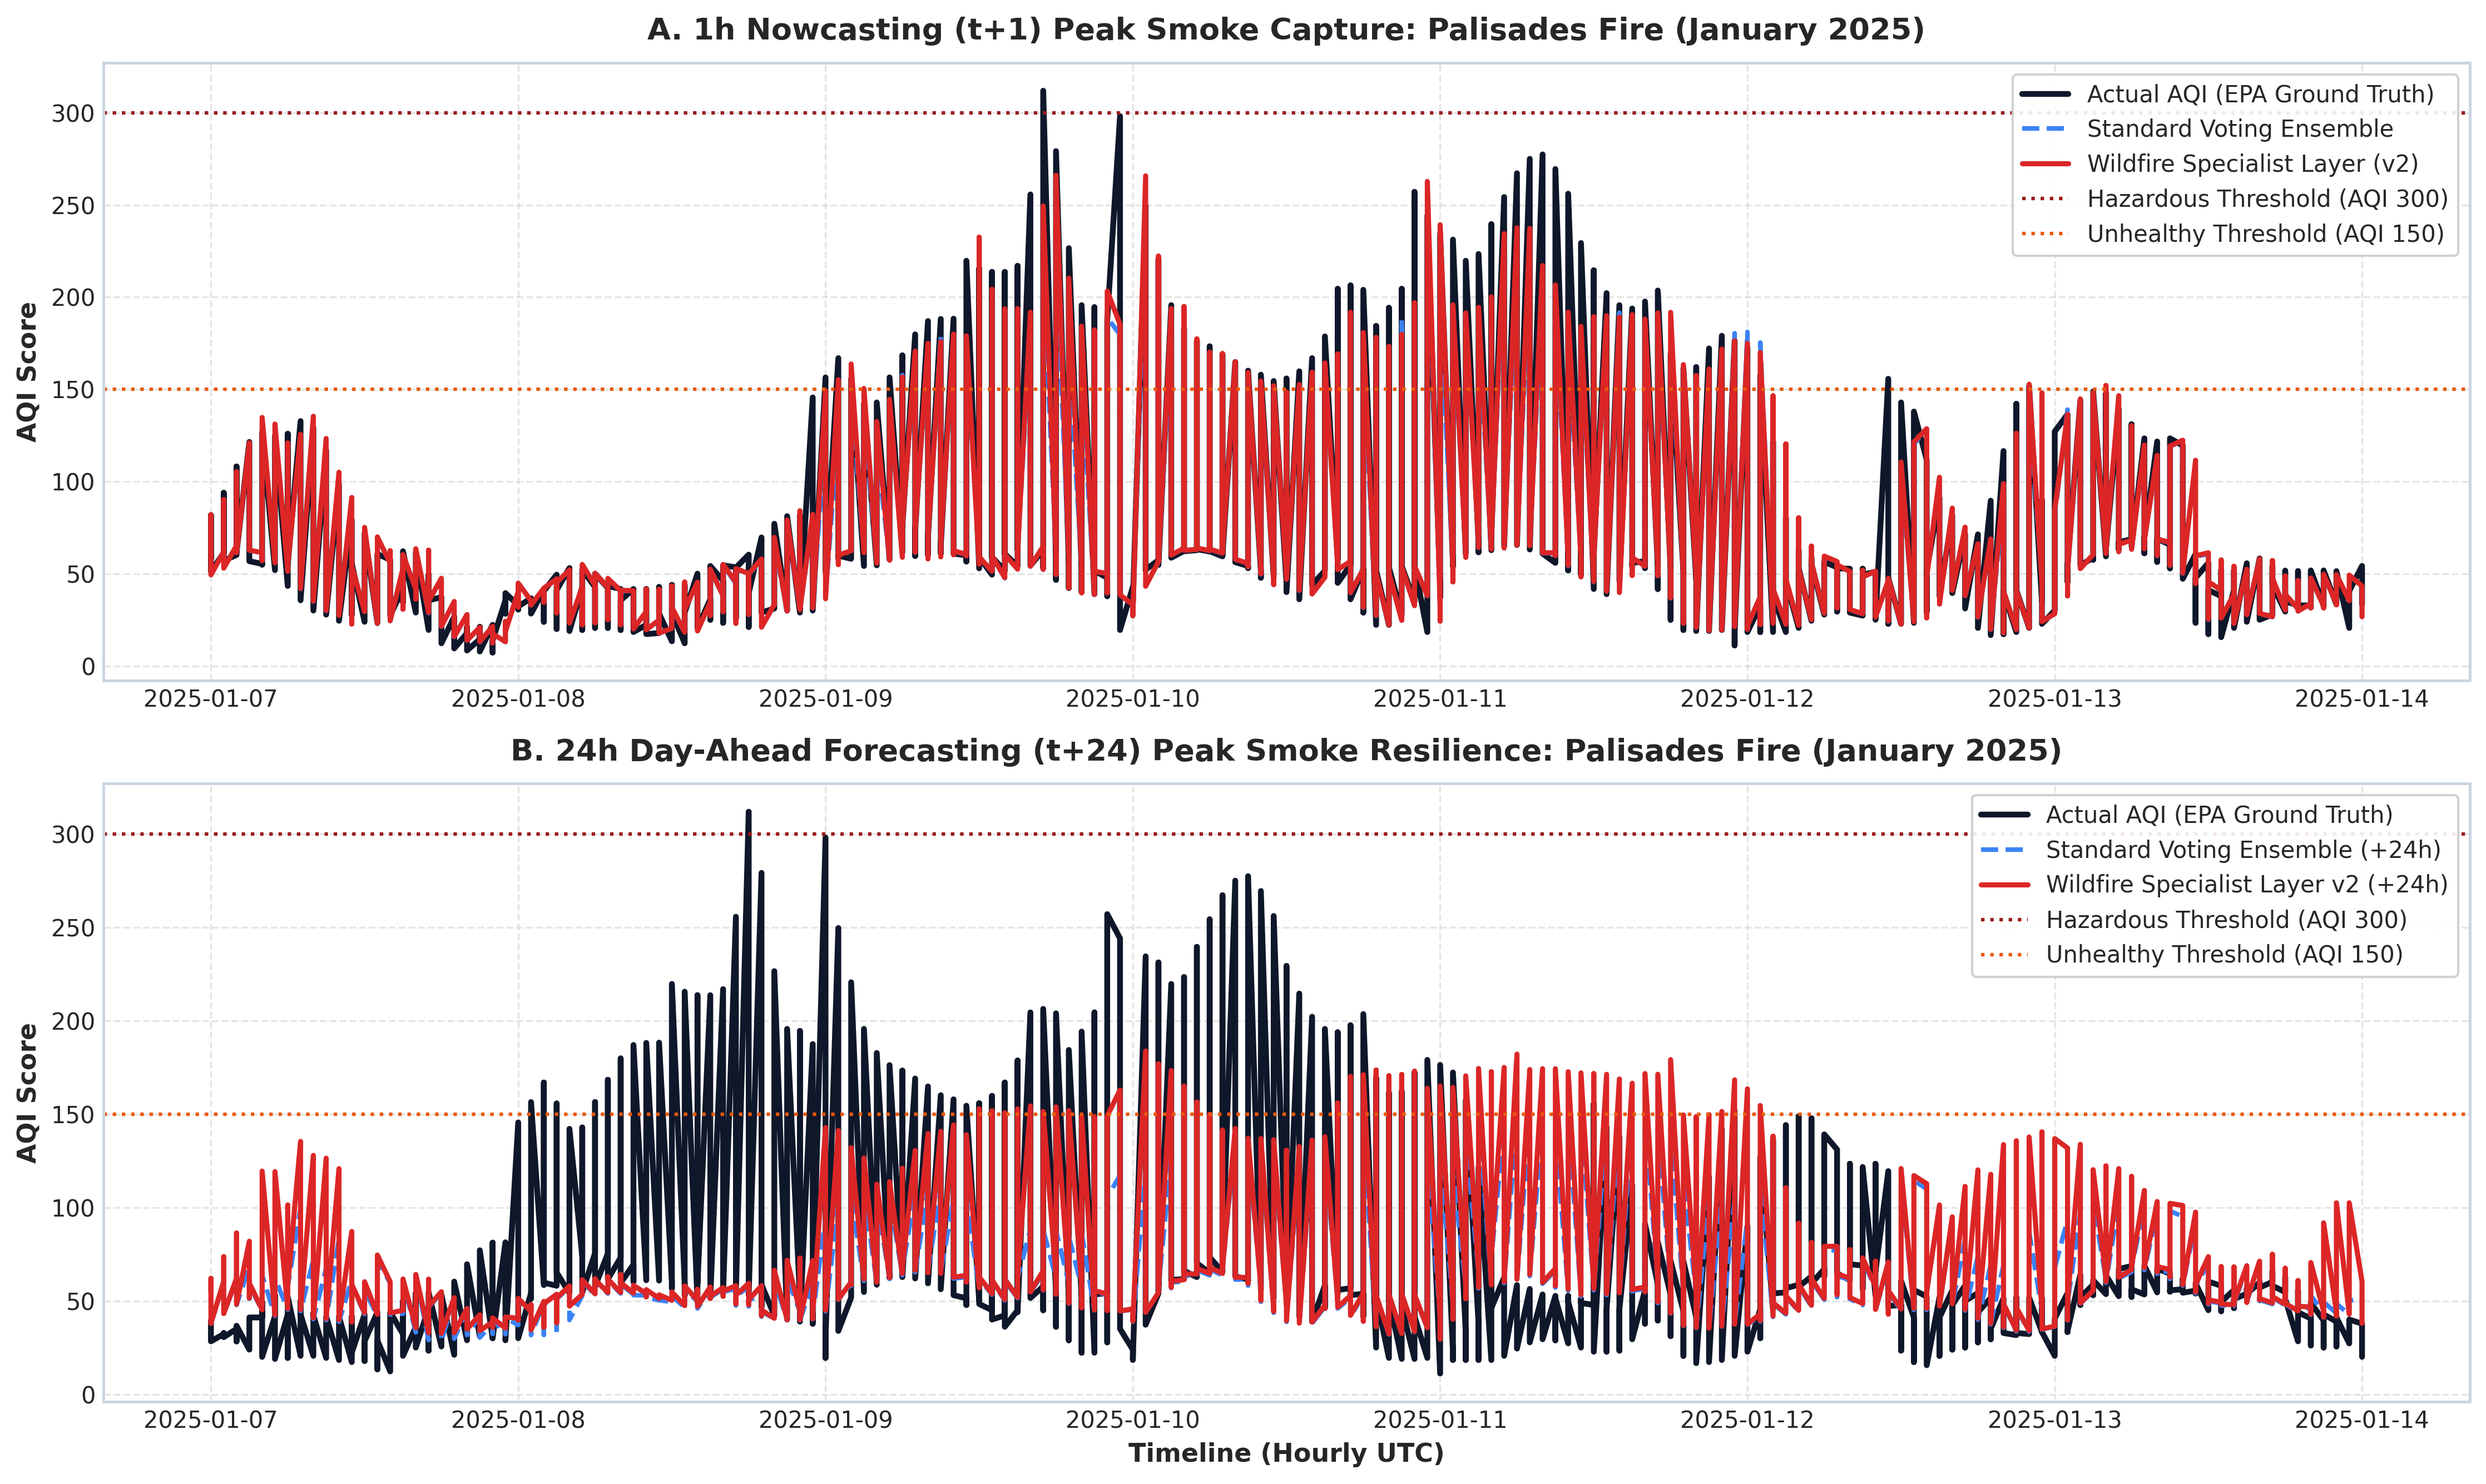

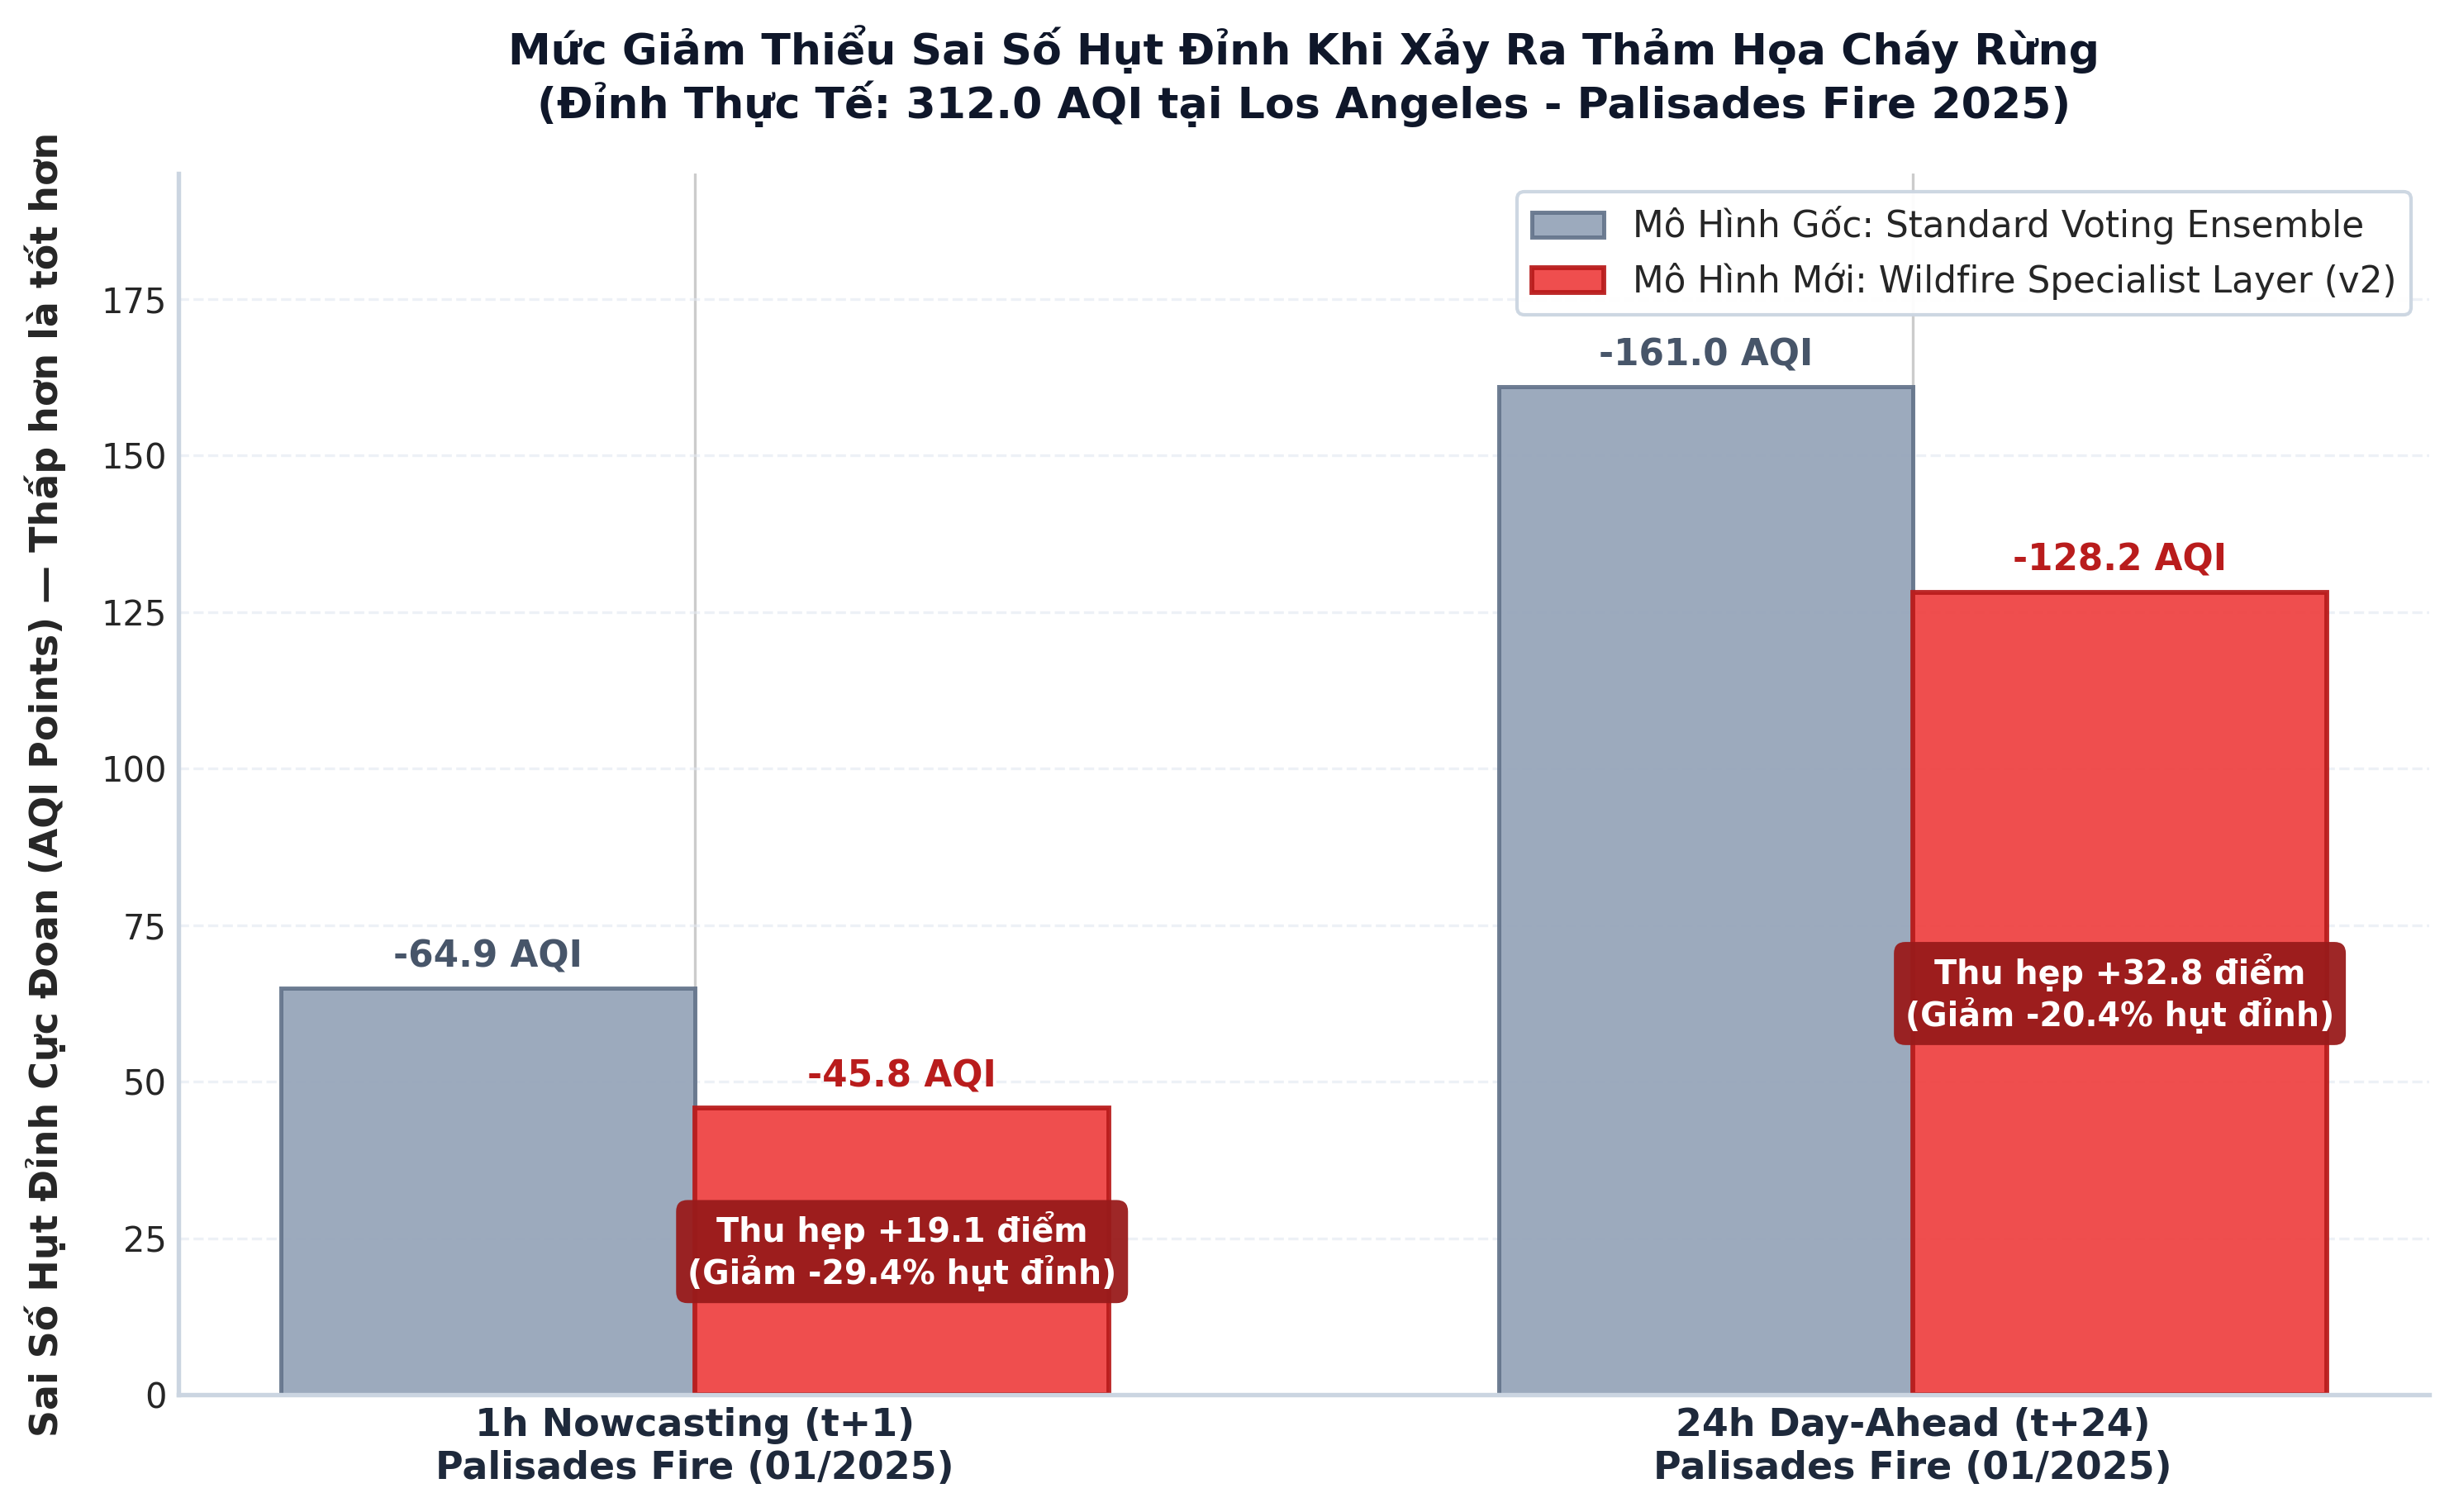

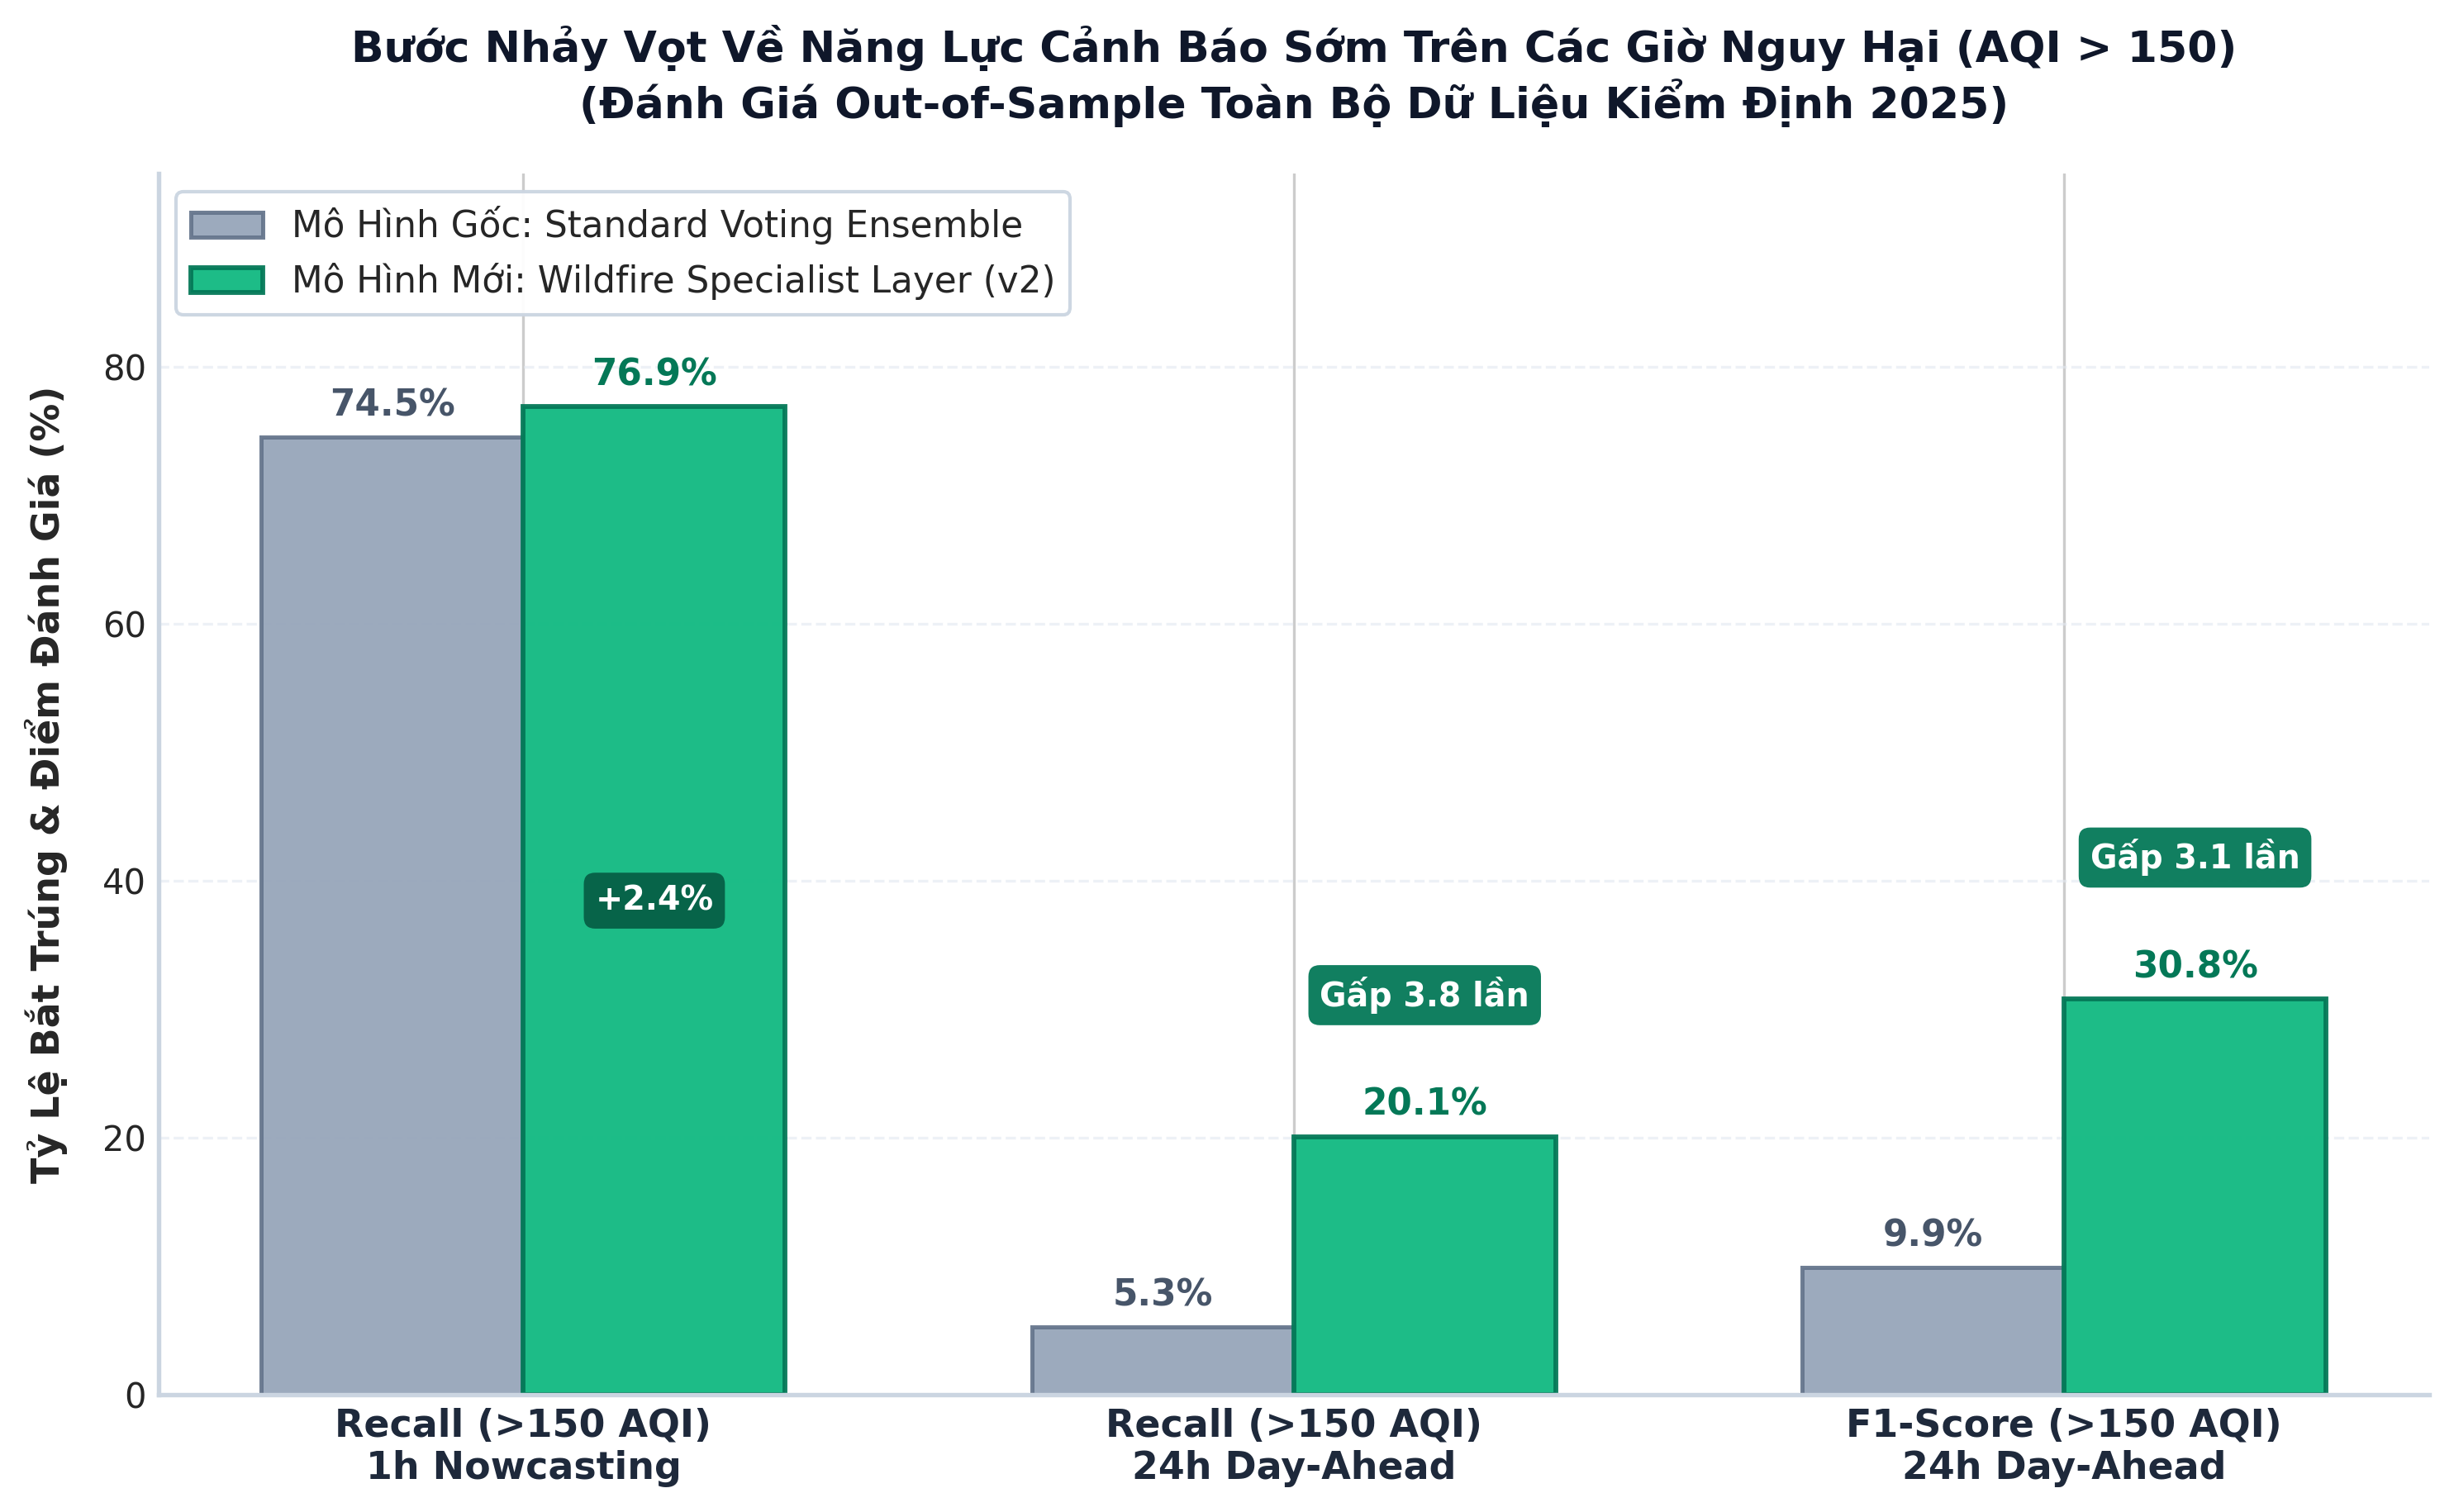

In [5]:
from IPython.display import Image, display
display(Image(filename=f"{FIG_DIR}/11_wildfire_layer_peak_comparison.png"))
display(Image(filename=f"{FIG_DIR}/12_wildfire_peak_reduction.png"))
display(Image(filename=f"{FIG_DIR}/13_wildfire_recall_f1_jump.png"))